In [ ]:
!unzip "archive (2).zip"

Archive:  archive (2).zip
  inflating: DNS-testing.parquet     
  inflating: LDAP-testing.parquet    
  inflating: LDAP-training.parquet   
  inflating: MSSQL-testing.parquet   
  inflating: MSSQL-training.parquet  
  inflating: NTP-testing.parquet     
  inflating: NetBIOS-testing.parquet  
  inflating: NetBIOS-training.parquet  
  inflating: Portmap-training.parquet  
  inflating: SNMP-testing.parquet    
  inflating: Syn-testing.parquet     
  inflating: Syn-training.parquet    
  inflating: TFTP-testing.parquet    
  inflating: UDP-testing.parquet     
  inflating: UDP-training.parquet    
  inflating: UDPLag-testing.parquet  
  inflating: UDPLag-training.parquet  


In [ ]:
import os
print(os.listdir())

['.config', 'archive (2).zip', 'UDP-testing.parquet', 'UDP-training.parquet', 'MSSQL-training.parquet', 'SNMP-testing.parquet', 'Portmap-training.parquet', 'NetBIOS-training.parquet', 'NetBIOS-testing.parquet', 'LDAP-training.parquet', 'drive', 'Syn-training.parquet', 'UDPLag-training.parquet', 'TFTP-testing.parquet', 'DNS-testing.parquet', 'MSSQL-testing.parquet', 'LDAP-testing.parquet', 'UDPLag-testing.parquet', 'NTP-testing.parquet', 'Syn-testing.parquet', 'sample_data']


In [ ]:
import os

for root, dirs, files in os.walk("."):
    print("Folder:", root)
    print("Files:", files[:5])  # show few files
    print("------")

Folder: .
Files: ['archive (2).zip', 'UDP-testing.parquet', 'UDP-training.parquet', 'MSSQL-training.parquet', 'SNMP-testing.parquet']
------
Folder: ./.config
Files: ['hidden_gcloud_config_universe_descriptor_data_cache_configs.db', 'default_configs.db', 'gce', '.last_opt_in_prompt.yaml', '.last_survey_prompt.yaml']
------
Folder: ./.config/logs
Files: []
------
Folder: ./.config/logs/2026.03.23
Files: ['13.29.47.572748.log', '13.29.34.829749.log', '13.29.24.904753.log', '13.29.02.727930.log', '13.29.46.856905.log']
------
Folder: ./.config/configurations
Files: ['config_default']
------
Folder: ./drive
Files: []
------
Folder: ./drive/.shortcut-targets-by-id
Files: []
------
Folder: ./drive/MyDrive
Files: ['1599026044339-1897325745.jpg', '1599026482381264995547.jpg', '15991054996591699976368.jpg', '1599109123246-947464966.jpg', '1599543923206-801580041.jpg']
------
Folder: ./drive/MyDrive/Colab Notebooks
Files: ['Hybrid DDOS detection .ipynb', 'Logistic Regression.ipynb', 'Copy of Unt

In [ ]:
import os

files = os.listdir()

training_files = [f for f in files if "training" in f.lower()]
testing_files = [f for f in files if "testing" in f.lower()]

print("Training files:", training_files)
print("Testing files:", testing_files)

Training files: ['UDP-training.parquet', 'MSSQL-training.parquet', 'Portmap-training.parquet', 'NetBIOS-training.parquet', 'LDAP-training.parquet', 'Syn-training.parquet', 'UDPLag-training.parquet']
Testing files: ['UDP-testing.parquet', 'SNMP-testing.parquet', 'NetBIOS-testing.parquet', 'TFTP-testing.parquet', 'DNS-testing.parquet', 'MSSQL-testing.parquet', 'LDAP-testing.parquet', 'UDPLag-testing.parquet', 'NTP-testing.parquet', 'Syn-testing.parquet']


In [ ]:
import pandas as pd

train_data = pd.concat([pd.read_parquet(f) for f in training_files], ignore_index=True)
test_data = pd.concat([pd.read_parquet(f) for f in testing_files], ignore_index=True)

print("Data loaded successfully ✅")
print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)

Data loaded successfully ✅
Train shape: (125170, 78)
Test shape: (306201, 78)


In [ ]:
train_data['Label'] = train_data['Label'].astype(str)
train_data['Label'] = train_data['Label'].apply(lambda x: 0 if x.lower() == 'benign' else 1)

test_data['Label'] = test_data['Label'].astype(str)
test_data['Label'] = test_data['Label'].apply(lambda x: 0 if x.lower() == 'benign' else 1)

print(train_data['Label'].value_counts())

Label
1    78743
0    46427
Name: count, dtype: int64


Feature Split

In [ ]:
X_train = train_data.drop('Label', axis=1)
y_train = train_data['Label']

X_test = test_data.drop('Label', axis=1)
y_test = test_data['Label']

print(X_train.shape)

(125170, 77)


Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling done ✅")

Scaling done ✅


Baseline RF

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("RF Accuracy:", rf_accuracy)

RF Accuracy: 0.9727956473035686


Principal Component Analysis

In [ ]:
from sklearn.decomposition import PCA

# choose components (try 32 or 64)
pca = PCA(n_components=64)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("PCA applied ✅")
print("New shape:", X_train_pca.shape)

PCA applied ✅
New shape: (125170, 64)


Train RF on PCA

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_pca = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

rf_pca.fit(X_train_pca, y_train)

y_pred_pca = rf_pca.predict(X_test_pca)

pca_accuracy = accuracy_score(y_test, y_pred_pca)

print("PCA + RF Accuracy:", pca_accuracy)

PCA + RF Accuracy: 0.8801669491608454


Explained Variance

In [ ]:
print("Explained Variance Ratio:", sum(pca.explained_variance_ratio_))

Explained Variance Ratio: 1.0000000000000002


Built Autoencoder

In [ ]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

input_dim = X_train_scaled.shape[1]

input_layer = Input(shape=(input_dim,))

encoded = Dense(128, activation='relu')(input_layer)
encoded = Dense(64, activation='relu')(encoded)

decoded = Dense(128, activation='relu')(encoded)
decoded = Dense(input_dim, activation='sigmoid')(decoded)

autoencoder = Model(inputs=input_layer, outputs=decoded)

autoencoder.compile(optimizer='adam', loss='mse')

print("Autoencoder built ✅")

Autoencoder built ✅


Train Autoencoder

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

es = EarlyStopping(patience=3, restore_best_weights=True)

autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    callbacks=[es]
)

print("Autoencoder trained ✅")

Epoch 1/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 0.6011 - val_loss: 0.5798
Epoch 2/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.5794 - val_loss: 0.5781
Epoch 3/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5789 - val_loss: 0.5780
Epoch 4/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5784 - val_loss: 0.5760
Epoch 5/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5770 - val_loss: 0.5681
Epoch 6/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.5750 - val_loss: 0.5676
Epoch 7/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5748 - val_loss: 0.5672
Epoch 8/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5717 - val_loss: 0.5558
Epoch 9/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5705 - val_loss: 0.5556
Epoch 10/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5706 - val_loss: 0.5555
Epoch 11/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.5705 - val_loss: 0.5553
Epoch 12/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step

Extract Encoded Features

In [ ]:
encoder = Model(inputs=input_layer, outputs=encoded)

X_train_encoded = encoder.predict(X_train_scaled)
X_test_encoded = encoder.predict(X_test_scaled)

print("Encoded features created ✅")
print(X_train_encoded.shape)

3912/3912 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step
9569/9569 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step
Encoded features created ✅
(125170, 64)


Hybrid Model (Autoencoder + RF)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_hybrid = RandomForestClassifier(
    n_estimators=300,
    max_depth=30,
    min_samples_split=3,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_hybrid.fit(X_train_encoded, y_train)

y_pred_hybrid = rf_hybrid.predict(X_test_encoded)

hybrid_accuracy = accuracy_score(y_test, y_pred_hybrid)

print("Hybrid Accuracy:", hybrid_accuracy)

Hybrid Accuracy: 0.9964892341958387


Autoencoder Standlone accuracy

In [ ]:
import numpy as np

X_test_pred = autoencoder.predict(X_test_scaled)

reconstruction_error = np.mean(np.square(X_test_scaled - X_test_pred), axis=1)

threshold = np.percentile(reconstruction_error, 95)

y_pred_ae = (reconstruction_error > threshold).astype(int)

ae_accuracy = accuracy_score(y_test, y_pred_ae)

print("Autoencoder Accuracy:", ae_accuracy)

9569/9569 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step
Autoencoder Accuracy: 0.2173800869363588


Final Comparsion Table

In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "PCA + RF",
        "Autoencoder",
        "Hybrid"
    ],
    "Accuracy": [
        rf_accuracy,
        pca_accuracy,
        ae_accuracy,
        hybrid_accuracy
    ]
})

print(comparison)

           Model  Accuracy
0  Random Forest  0.972796
1       PCA + RF  0.880167
2    Autoencoder  0.217380
3         Hybrid  0.996489


ROC CURVE

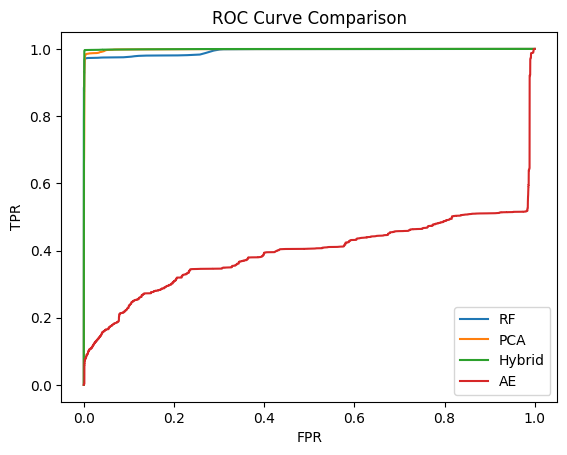

<Figure size 640x480 with 0 Axes>

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# RF
y_prob_rf = rf.predict_proba(X_test)[:,1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# PCA
y_prob_pca = rf_pca.predict_proba(X_test_pca)[:,1]
fpr_pca, tpr_pca, _ = roc_curve(y_test, y_prob_pca)

# Hybrid
y_prob_hybrid = rf_hybrid.predict_proba(X_test_encoded)[:,1]
fpr_hybrid, tpr_hybrid, _ = roc_curve(y_test, y_prob_hybrid)

# AE
fpr_ae, tpr_ae, _ = roc_curve(y_test, reconstruction_error)

plt.plot(fpr_rf, tpr_rf, label="RF")
plt.plot(fpr_pca, tpr_pca, label="PCA")
plt.plot(fpr_hybrid, tpr_hybrid, label="Hybrid")
plt.plot(fpr_ae, tpr_ae, label="AE")

plt.legend()
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC Curve Comparison")
plt.show()

# 🔥 ADD THIS LINE
plt.savefig("roc_curve.png", dpi=300, bbox_inches='tight')

plt.show()

TRAINING TIME

In [ ]:
#Random Forest(Baseline)
import time

start = time.time()

rf.fit(X_train, y_train)

rf_time = time.time() - start

print("RF Training Time:", rf_time)



RF Training Time: 54.42013168334961


In [ ]:
#PCA + RF
start = time.time()

rf_pca.fit(X_train_pca, y_train)

pca_time = time.time() - start

print("PCA Training Time:", pca_time)



PCA Training Time: 394.01104402542114


In [ ]:
#Autoencoder
start = time.time()

autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=30,
    batch_size=128,
    validation_split=0.2
)

ae_time = time.time() - start

print("Autoencoder Training Time:", ae_time)



Epoch 1/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5700 - val_loss: 0.5540
Epoch 2/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5700 - val_loss: 0.5537
Epoch 3/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.5700 - val_loss: 0.5537
Epoch 4/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5700 - val_loss: 0.5537
Epoch 5/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.5700 - val_loss: 0.5537
Epoch 6/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5699 - val_loss: 0.5538
Epoch 7/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.5697 - val_loss: 0.5524
Epoch 8/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5697 - val_loss: 0.5524
Epoch 9/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5696 - val_loss: 0.5524
Epoch 10/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5696 - val_loss: 0.5523
Epoch 11/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.5696 - val_loss: 0.5526
Epoch 12/30
783/783 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step

In [ ]:
#Hybrid
start = time.time()

rf_hybrid.fit(X_train_encoded, y_train)

hybrid_time = time.time() - start

print("Hybrid Training Time:", hybrid_time)

Hybrid Training Time: 453.16816687583923


Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix
#RF
cm_rf = confusion_matrix(y_test, y_pred_rf)
print("RF Confusion Matrix:\n", cm_rf)
#PCA
cm_pca = confusion_matrix(y_test, y_pred_pca)
print("PCA Confusion Matrix:\n", cm_pca)
#Hybrid
cm_hybrid = confusion_matrix(y_test, y_pred_hybrid)
print("Hybrid Confusion Matrix:\n", cm_hybrid)
#Autoencoder
cm_ae = confusion_matrix(y_test, y_pred_ae)
print("Autoencoder Confusion Matrix:\n", cm_ae)

RF Confusion Matrix:
 [[ 51330     74]
 [  8256 246541]]
PCA Confusion Matrix:
 [[ 51350     54]
 [ 36639 218158]]
Hybrid Confusion Matrix:
 [[ 51307     97]
 [   978 253819]]
Autoencoder Confusion Matrix:
 [[ 51328     76]
 [239563  15234]]


PLot Confusion Matrix of RF

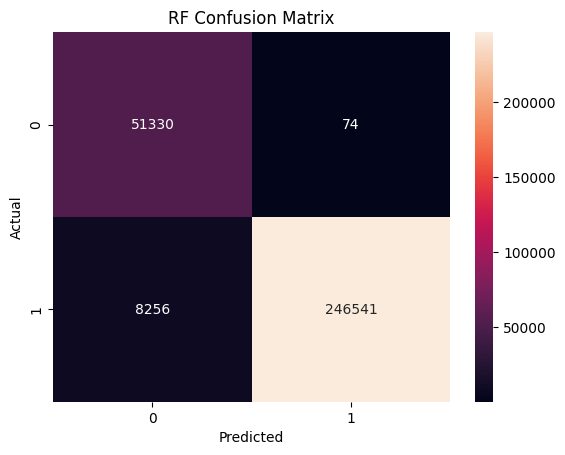

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm_rf, annot=True, fmt='d')
plt.title("RF Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Autoencoder plot

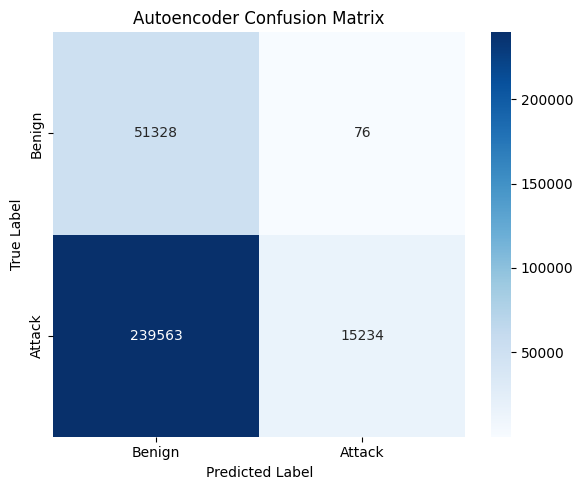

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# compute confusion matrix
cm_ae = confusion_matrix(y_test, y_pred_ae)

# plot
plt.figure(figsize=(6,5))

sns.heatmap(cm_ae, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Benign", "Attack"],
            yticklabels=["Benign", "Attack"])

plt.title("Autoencoder Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

Hybrid Confusion PLot

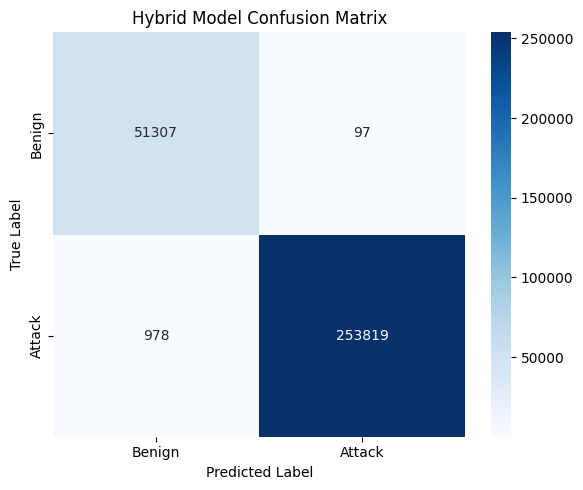

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# compute confusion matrix
cm_hybrid = confusion_matrix(y_test, y_pred_hybrid)

# plot
plt.figure(figsize=(6,5))
sns.heatmap(cm_hybrid, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Benign", "Attack"],
            yticklabels=["Benign", "Attack"])

plt.title("Hybrid Model Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

f=Final Comparsion Table

In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["RF", "PCA + RF", "Autoencoder", "Hybrid"],
    "Accuracy": [rf_accuracy, pca_accuracy, ae_accuracy, hybrid_accuracy],
    "Training Time (s)": [rf_time, pca_time, ae_time, hybrid_time]
})

print(comparison)

         Model  Accuracy  Training Time (s)
0           RF  0.972796          54.420132
1     PCA + RF  0.880167         394.011044
2  Autoencoder  0.217380         112.063272
3       Hybrid  0.996489         453.168167


Figure 5: Probability of Test Samples Being Classified as Attack

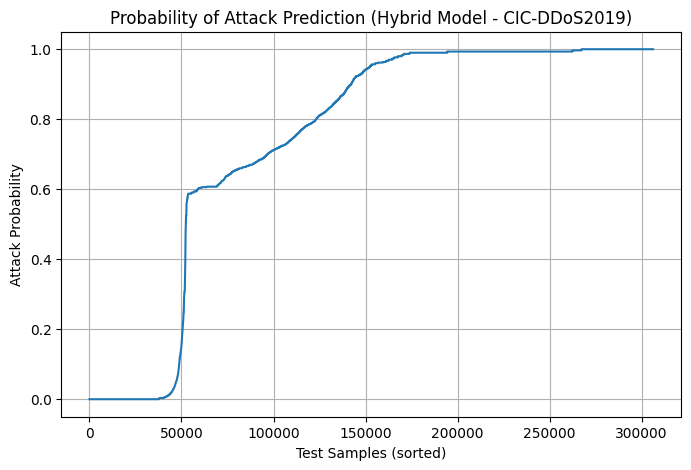

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
y_prob_hybrid = rf_hybrid.predict_proba(X_test_encoded)[:, 1]

import numpy as np
import matplotlib.pyplot as plt

sorted_probs = np.sort(y_prob_hybrid)

plt.figure(figsize=(8,5))
plt.plot(sorted_probs)

plt.xlabel("Test Samples (sorted)")
plt.ylabel("Attack Probability")
plt.title("Probability of Attack Prediction (Hybrid Model - CIC-DDoS2019)")
plt.grid()


plt.show()


Figure 6: Reconstruction Error (MSE) of Test Samples using Autoencoder

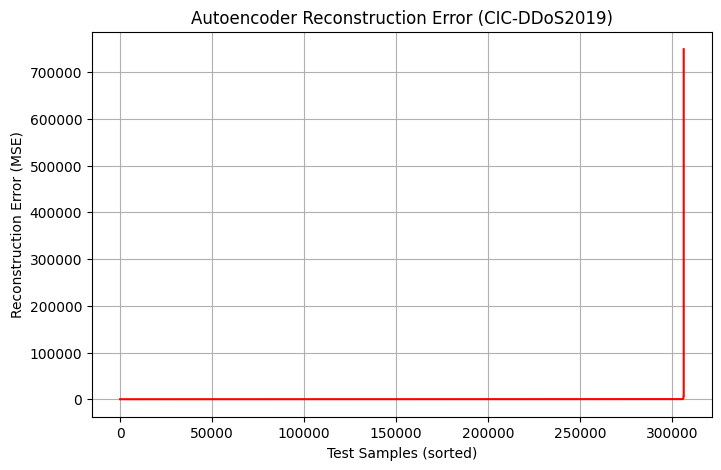

In [ ]:
sorted_error = np.sort(reconstruction_error)

plt.figure(figsize=(8,5))
plt.plot(sorted_error, color='red')

plt.xlabel("Test Samples (sorted)")
plt.ylabel("Reconstruction Error (MSE)")
plt.title("Autoencoder Reconstruction Error (CIC-DDoS2019)")
plt.grid()

plt.show()

dataset does NOT directly label “unknown attack”
So we simulate it like research papers do:

✔ Train on some attack types (known)
✔ Test on different attack types (unknown)

Define Known vs Unknown Attacks

In [ ]:
# Example attack split
known_attacks = ['Syn', 'UDP']
unknown_attacks = ['LDAP', 'NetBIOS', 'MSSQL']

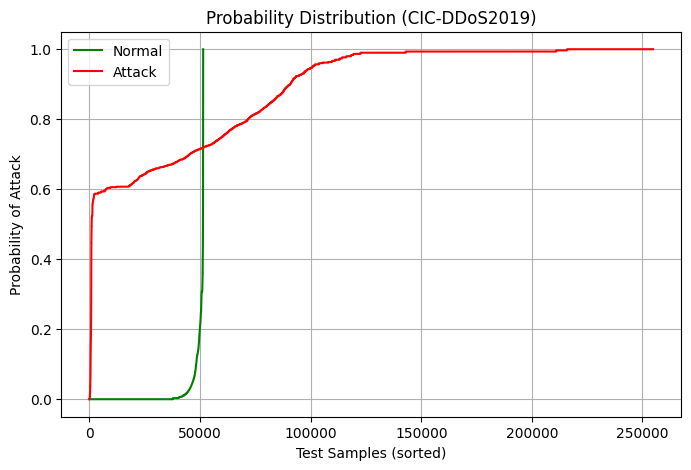

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get probabilities
y_prob = rf_hybrid.predict_proba(X_test_encoded)[:,1]

# Separate classes
normal_idx = (y_test == 0)
attack_idx = (y_test == 1)

# Sort values
normal_probs = np.sort(y_prob[normal_idx])
attack_probs = np.sort(y_prob[attack_idx])

plt.figure(figsize=(8,5))

plt.plot(normal_probs, label="Normal", color='green')
plt.plot(attack_probs, label="Attack", color='red')

plt.xlabel("Test Samples (sorted)")
plt.ylabel("Probability of Attack")
plt.title("Probability Distribution (CIC-DDoS2019)")
plt.legend()
plt.grid()

plt.show()

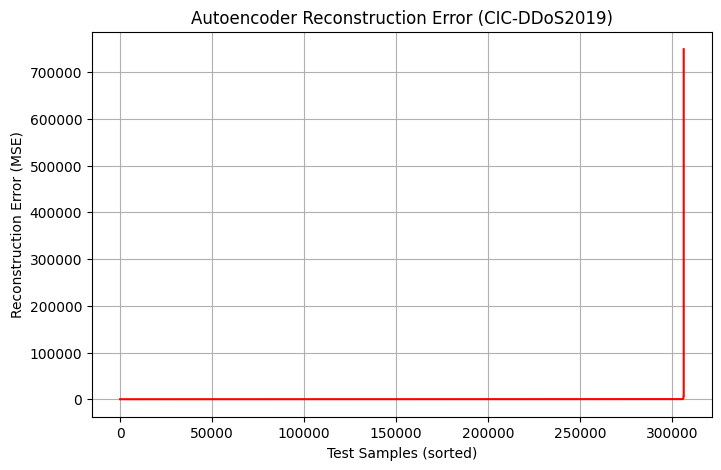

In [ ]:
sorted_error = np.sort(reconstruction_error)

plt.figure(figsize=(8,5))
plt.plot(sorted_error, color='red')

plt.xlabel("Test Samples (sorted)")
plt.ylabel("Reconstruction Error (MSE)")
plt.title("Autoencoder Reconstruction Error (CIC-DDoS2019)")
plt.grid()

plt.show()

In [ ]:
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

def plot_cm_percent(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100

    plt.figure(figsize=(5,4))
    sns.heatmap(cm_percent, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=["Benign","Attack"],
                yticklabels=["Benign","Attack"])

    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

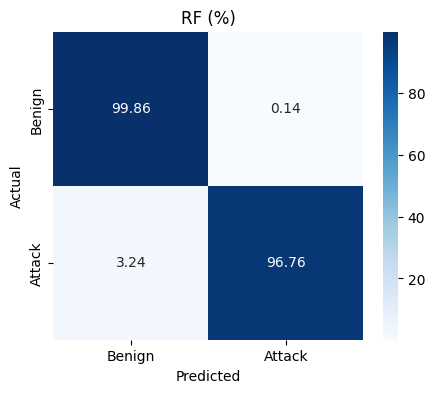

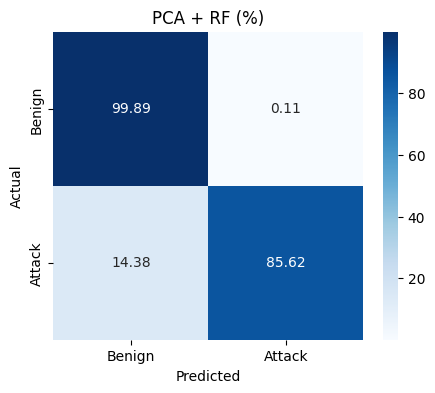

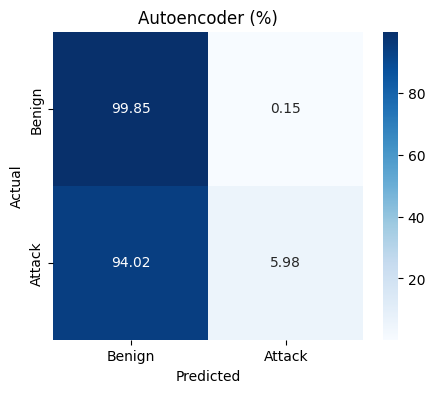

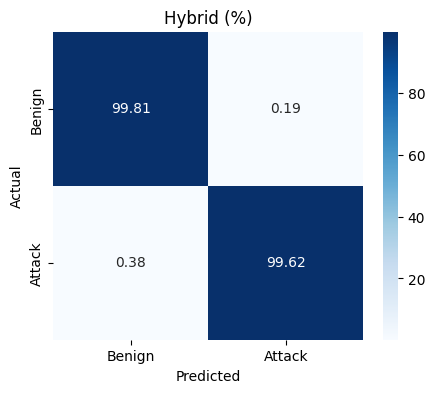

In [ ]:
plot_cm_percent(y_test, y_pred_rf, "RF (%)")
plot_cm_percent(y_test, y_pred_pca, "PCA + RF (%)")
plot_cm_percent(y_test, y_pred_ae, "Autoencoder (%)")
plot_cm_percent(y_test, y_pred_hybrid, "Hybrid (%)")

In [ ]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from google.colab import files

def plot_cm_percent(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred)
    cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100

    fig, ax = plt.subplots(figsize=(5,4))

    sns.heatmap(cm_percent, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=["Benign","Attack"],
                yticklabels=["Benign","Attack"],
                ax=ax)

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    plt.tight_layout()

    # 🔥 Save
    fig.savefig(filename, dpi=300, bbox_inches='tight')

    plt.show()
    plt.close()

    # 🔥 Download immediately
    files.download(filename)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

def get_metrics(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred),
        recall_score(y_true, y_pred),
        f1_score(y_true, y_pred)
    ]

data = [
    ["RF"] + get_metrics(y_test, y_pred_rf),
    ["PCA+RF"] + get_metrics(y_test, y_pred_pca),
    ["AE"] + get_metrics(y_test, y_pred_ae),
    ["Hybrid"] + get_metrics(y_test, y_pred_hybrid)
]

import pandas as pd

table = pd.DataFrame(data, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1-Score"
])

print(table)

    Model  Accuracy  Precision    Recall  F1-Score
0      RF  0.972796   0.999700  0.967598  0.983387
1  PCA+RF  0.880167   0.999753  0.856203  0.922426
2      AE  0.217380   0.995036  0.059789  0.112800
3  Hybrid  0.996489   0.999618  0.996162  0.997887


BEST GRAPH: Model vs Metrics

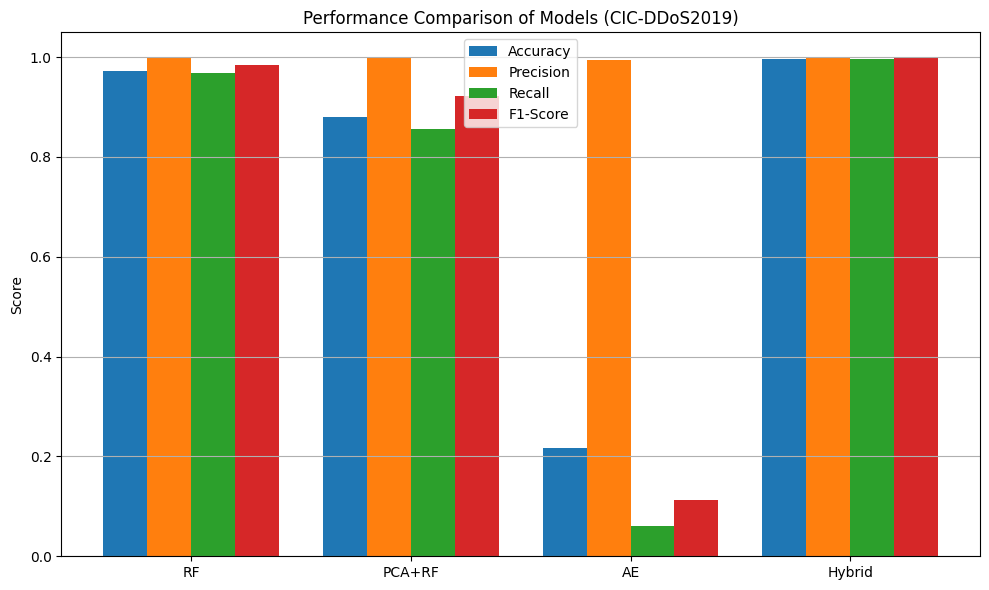

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Models
models = ['RF', 'PCA+RF', 'AE', 'Hybrid']

# Metrics
accuracy = [0.972796, 0.880167, 0.217380, 0.996489]
precision = [0.999700, 0.999753, 0.995036, 0.999618]
recall = [0.967598, 0.856203, 0.059789, 0.996162]
f1 = [0.983387, 0.922426, 0.112800, 0.997887]

# X-axis
x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(10,6))

plt.bar(x - 1.5*width, accuracy, width, label='Accuracy')
plt.bar(x - 0.5*width, precision, width, label='Precision')
plt.bar(x + 0.5*width, recall, width, label='Recall')
plt.bar(x + 1.5*width, f1, width, label='F1-Score')

plt.xticks(x, models)
plt.ylabel("Score")
plt.title("Performance Comparison of Models (CIC-DDoS2019)")
plt.legend()
plt.grid(axis='y')

plt.tight_layout()
plt.show()


Line Graph

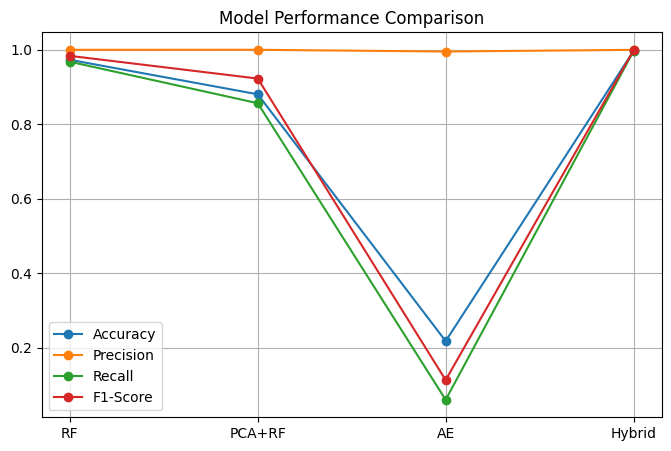

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(models, accuracy, marker='o', label='Accuracy')
plt.plot(models, precision, marker='o', label='Precision')
plt.plot(models, recall, marker='o', label='Recall')
plt.plot(models, f1, marker='o', label='F1-Score')

plt.title("Model Performance Comparison")
plt.legend()
plt.grid()

plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def get_metrics(y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    if y_prob is not None:
        auc = roc_auc_score(y_true, y_prob)
    else:
        auc = 0

    return [acc, prec, rec, f1, auc]

In [ ]:
data = []

# RF
data.append(["RF"] + get_metrics(y_test, y_pred_rf, rf.predict_proba(X_test)[:,1]))

# PCA
data.append(["PCA+RF"] + get_metrics(y_test, y_pred_pca, rf_pca.predict_proba(X_test_pca)[:,1]))

# Autoencoder (no prob)
data.append(["AE"] + get_metrics(y_test, y_pred_ae))

# Hybrid
data.append(["Hybrid"] + get_metrics(y_test, y_pred_hybrid, rf_hybrid.predict_proba(X_test_encoded)[:,1]))

In [ ]:
import pandas as pd

table = pd.DataFrame(data, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1-Score", "AUC"
])

print(table)

    Model  Accuracy  Precision    Recall  F1-Score       AUC
0      RF  0.972796   0.999700  0.967598  0.983387  0.993652
1  PCA+RF  0.880167   0.999753  0.856203  0.922426  0.998609
2      AE  0.217380   0.995036  0.059789  0.112800  0.000000
3  Hybrid  0.996489   0.999618  0.996162  0.997887  0.999304


In [ ]:
mean_values = table.mean(numeric_only=True)
std_values = table.std(numeric_only=True)

print("Mean:\n", mean_values)
print("\nStd Dev:\n", std_values)

Mean:
 Accuracy     0.766708
Precision    0.998527
Recall       0.719938
F1-Score     0.754125
AUC          0.747891
dtype: float64

Std Dev:
 Accuracy     0.369642
Precision    0.002328
Recall       0.444222
F1-Score     0.428798
AUC          0.498601
dtype: float64


In [ ]:
data_list = []

for file in testing_files:
    df = pd.read_parquet(file)

    # extract attack type from filename
    attack_type = file.split('-')[0]

    df['Attack_Type'] = attack_type

    data_list.append(df)

test_data = pd.concat(data_list, ignore_index=True)

In [ ]:
attack_types = test_data['Attack_Type'].unique()
print(attack_types)

['UDP' 'SNMP' 'NetBIOS' 'TFTP' 'DNS' 'MSSQL' 'LDAP' 'UDPLag' 'NTP' 'Syn']


In [ ]:
c
print("F1 values calculated ✅")

F1 values calculated ✅


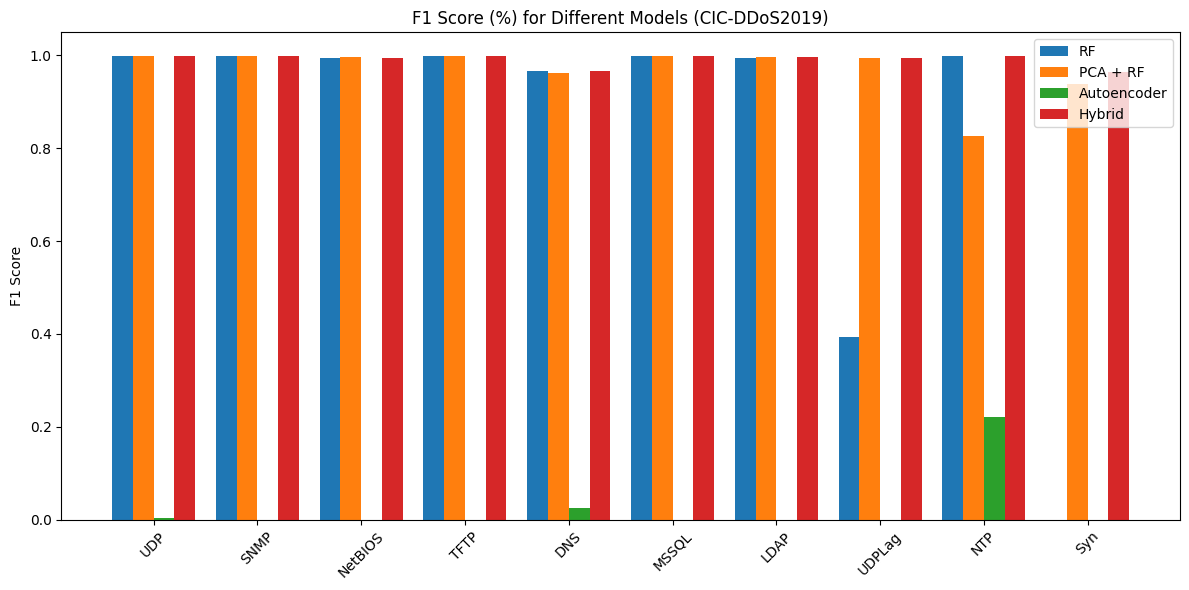

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(attack_types))

plt.figure(figsize=(12,6))

plt.bar(x - 0.3, f1_rf, width=0.2, label='RF')
plt.bar(x - 0.1, f1_pca, width=0.2, label='PCA + RF')
plt.bar(x + 0.1, f1_ae, width=0.2, label='Autoencoder')
plt.bar(x + 0.3, f1_hybrid, width=0.2, label='Hybrid')

plt.xticks(x, attack_types, rotation=45)
plt.ylabel("F1 Score")
plt.title("F1 Score (%) for Different Models (CIC-DDoS2019)")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix

fpr_rf = []
fpr_pca = []
fpr_ae = []
fpr_hybrid = []

for attack in attack_types:

    subset = test_data[test_data['Attack_Type'] == attack]
    idx = subset.index

    y_true_subset = y_test.loc[idx]

    y_rf = y_pred_rf[idx]
    y_pca = y_pred_pca[idx]
    y_ae = y_pred_ae[idx]
    y_hybrid = y_pred_hybrid[idx]

    def calc_fpr(y_true, y_pred):
        cm = confusion_matrix(y_true, y_pred)

        if cm.shape == (2,2):
            tn, fp, fn, tp = cm.ravel()
            return fp / (fp + tn + 1e-6)
        else:
            return 0

    fpr_rf.append(calc_fpr(y_true_subset, y_rf))
    fpr_pca.append(calc_fpr(y_true_subset, y_pca))
    fpr_ae.append(calc_fpr(y_true_subset, y_ae))
    fpr_hybrid.append(calc_fpr(y_true_subset, y_hybrid))

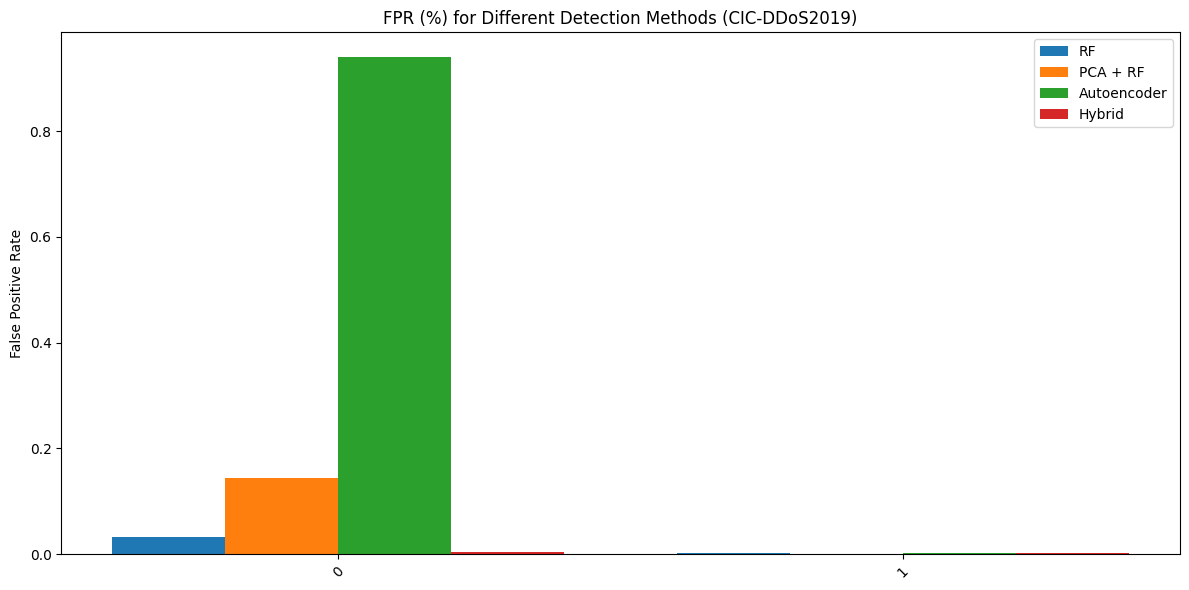

In [ ]:
plt.figure(figsize=(12,6))

plt.bar(x - 0.3, fpr_rf, width=0.2, label='RF')
plt.bar(x - 0.1, fpr_pca, width=0.2, label='PCA + RF')
plt.bar(x + 0.1, fpr_ae, width=0.2, label='Autoencoder')
plt.bar(x + 0.3, fpr_hybrid, width=0.2, label='Hybrid')

plt.xticks(x, attack_types, rotation=45)
plt.ylabel("False Positive Rate")
plt.title("FPR (%) for Different Detection Methods (CIC-DDoS2019)")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
thresholds = [80, 85, 90, 92, 95, 97, 99]

In [ ]:
from sklearn.metrics import confusion_matrix

fpr_rf = []
fpr_pca = []
fpr_ae = []
fpr_hybrid = []

for attack in attack_types:

    subset = test_data[test_data['Attack_Type'] == attack]
    idx = subset.index

    y_true_subset = y_test.loc[idx]

    y_rf = y_pred_rf[idx]
    y_pca = y_pred_pca[idx]
    y_ae = y_pred_ae[idx]
    y_hybrid = y_pred_hybrid[idx]

    def calc_fpr(y_true, y_pred):
        cm = confusion_matrix(y_true, y_pred)

        if cm.shape == (2,2):
            tn, fp, fn, tp = cm.ravel()
            return fp / (fp + tn + 1e-6)
        else:
            return 0

    fpr_rf.append(calc_fpr(y_true_subset, y_rf))
    fpr_pca.append(calc_fpr(y_true_subset, y_pca))
    fpr_ae.append(calc_fpr(y_true_subset, y_ae))
    fpr_hybrid.append(calc_fpr(y_true_subset, y_hybrid))

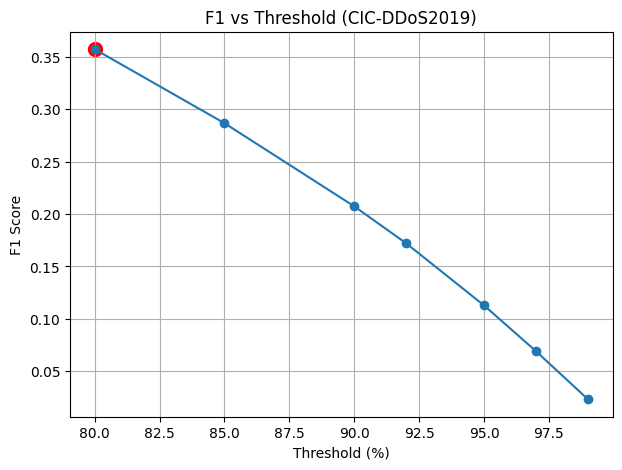

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.plot(thresholds, f1_scores, marker='o')

# highlight best point (red circle)
best_idx = np.argmax(f1_scores)
plt.scatter(thresholds[best_idx], f1_scores[best_idx], color='red', s=100)

plt.xlabel("Threshold (%)")
plt.ylabel("F1 Score")
plt.title("F1 vs Threshold (CIC-DDoS2019)")
plt.grid()

plt.show()


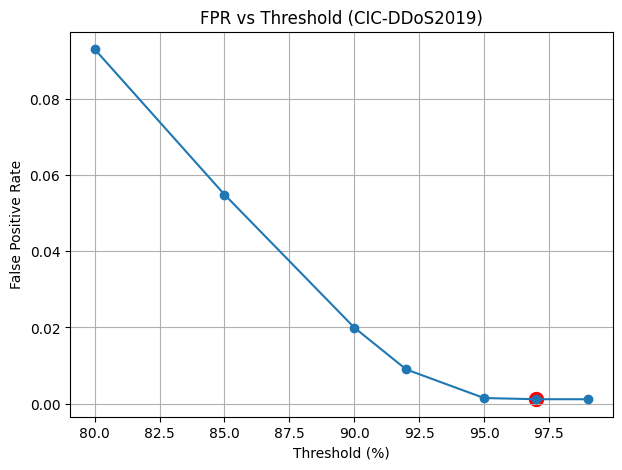

In [ ]:
plt.figure(figsize=(7,5))

plt.plot(thresholds, fpr_values, marker='o')

# highlight best (lowest FPR)
best_idx = np.argmin(fpr_values)
plt.scatter(thresholds[best_idx], fpr_values[best_idx], color='red', s=100)

plt.xlabel("Threshold (%)")
plt.ylabel("False Positive Rate")
plt.title("FPR vs Threshold (CIC-DDoS2019)")
plt.grid()

plt.show()

In [ ]:
import numpy as np

T1_values = [80, 85, 90, 95, 99]   # AE threshold (%)
T2_values = [65, 70, 75, 80, 85]   # Probability threshold (%)

In [ ]:
f1_matrix = np.zeros((len(T1_values), len(T2_values)))
fpr_matrix = np.zeros((len(T1_values), len(T2_values)))

In [ ]:
from sklearn.metrics import f1_score, confusion_matrix

for i, t1 in enumerate(T1_values):
    for j, t2 in enumerate(T2_values):

        # AE threshold
        th1 = np.percentile(reconstruction_error, t1)
        ae_pred = (reconstruction_error > th1).astype(int)

        # RF probability threshold
        y_prob = rf_hybrid.predict_proba(X_test_encoded)[:,1]
        th2 = t2 / 100
        rf_pred = (y_prob > th2).astype(int)

        # Combine (simple OR logic)
        final_pred = ((ae_pred + rf_pred) > 0).astype(int)

        # F1
        f1_matrix[i, j] = f1_score(y_test, final_pred) * 100

        # FPR
        cm = confusion_matrix(y_test, final_pred)

        if cm.shape == (2,2):
            tn, fp, fn, tp = cm.ravel()
            fpr_matrix[i, j] = (fp / (fp + tn + 1e-6)) * 100

F1 HeatMap

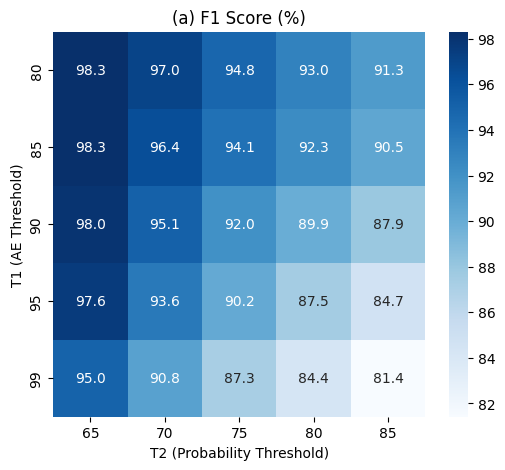

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.heatmap(f1_matrix, annot=True, fmt=".1f", cmap="Blues",
            xticklabels=T2_values,
            yticklabels=T1_values)

plt.xlabel("T2 (Probability Threshold)")
plt.ylabel("T1 (AE Threshold)")
plt.title("(a) F1 Score (%)")

plt.show()

FPR HeatMap

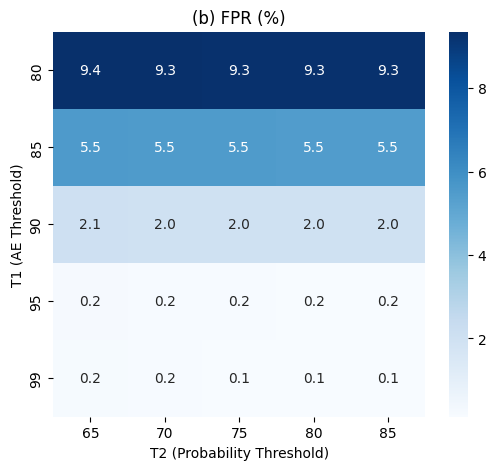

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(fpr_matrix, annot=True, fmt=".1f", cmap="Blues",
            xticklabels=T2_values,
            yticklabels=T1_values)

plt.xlabel("T2 (Probability Threshold)")
plt.ylabel("T1 (AE Threshold)")
plt.title("(b) FPR (%)")

plt.show()

Highlighting Best point

For F1 max

In [ ]:
max_idx = np.unravel_index(np.argmax(f1_matrix), f1_matrix.shape)
print("Best F1 at:", T1_values[max_idx[0]], T2_values[max_idx[1]])

Best F1 at: 80 65


For FPR max

In [ ]:
min_idx = np.unravel_index(np.argmin(fpr_matrix), fpr_matrix.shape)
print("Best FPR at:", T1_values[min_idx[0]], T2_values[min_idx[1]])

Best FPR at: 99 85


MSE distribution

 The MSE of testing samples for CIC-DDOS2019 dataset

In [ ]:
# Example split (adjust if needed)
known_attacks = ['Syn', 'UDP']
unknown_attacks = ['LDAP', 'NetBIOS']

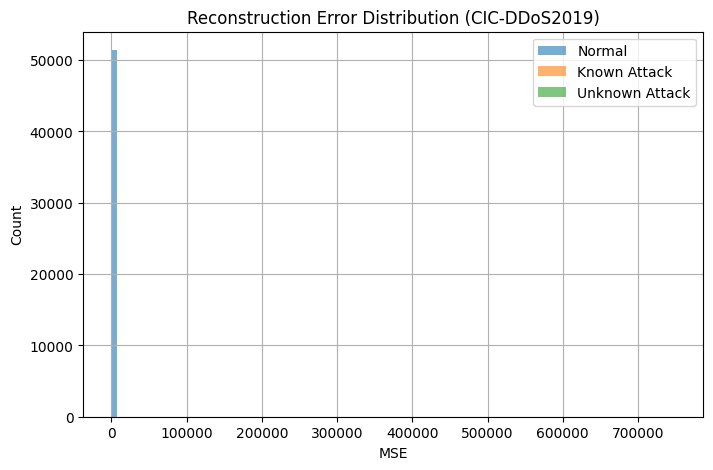

In [ ]:
#MSE histogram
import matplotlib.pyplot as plt

# masks
normal_idx = (y_test == 0)
attack_idx = (y_test == 1)

# If you created Attack_Type earlier:
known_idx = test_data['Attack_Type'].isin(known_attacks)
unknown_idx = test_data['Attack_Type'].isin(unknown_attacks)

plt.figure(figsize=(8,5))

# Normal
plt.hist(reconstruction_error[normal_idx], bins=100, alpha=0.6, label='Normal')

# Known Attack
plt.hist(reconstruction_error[known_idx], bins=100, alpha=0.6, label='Known Attack')

# Unknown Attack
plt.hist(reconstruction_error[unknown_idx], bins=100, alpha=0.6, label='Unknown Attack')

plt.xlabel("MSE")
plt.ylabel("Count")
plt.title("Reconstruction Error Distribution (CIC-DDoS2019)")
plt.legend()
plt.grid()

plt.show()

 The probability of being predicted as attacks for testing samples of CIC-DDOS2019 dataset when
DoS is unknown attack.

Probablity Distribution

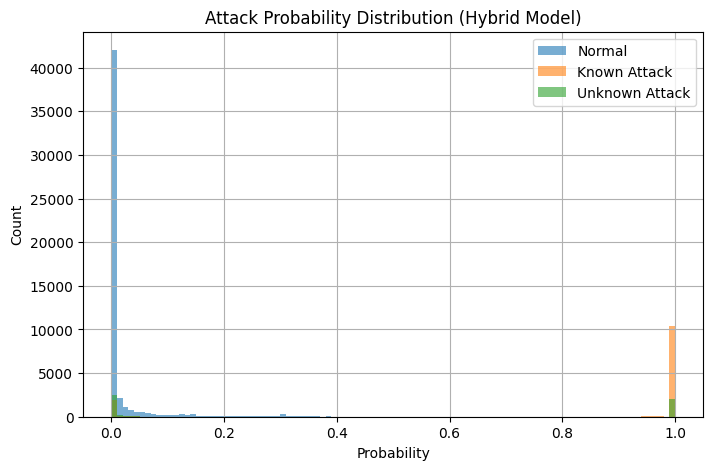

In [ ]:
y_prob = rf_hybrid.predict_proba(X_test_encoded)[:,1]

plt.figure(figsize=(8,5))

plt.hist(y_prob[normal_idx], bins=100, alpha=0.6, label='Normal')
plt.hist(y_prob[known_idx], bins=100, alpha=0.6, label='Known Attack')
plt.hist(y_prob[unknown_idx], bins=100, alpha=0.6, label='Unknown Attack')

plt.xlabel("Probability")
plt.ylabel("Count")
plt.title("Attack Probability Distribution (Hybrid Model)")
plt.legend()
plt.grid()

plt.show()

In [ ]:
import numpy as np

def format_metric(values):
    return f"{np.mean(values)*100:.2f} ± {np.std(values)*100:.2f}"

In [ ]:
table = []

table.append([
    "RF",
    f"{rf_accuracy*100:.2f}",
])

table.append([
    "PCA+RF",
    f"{pca_accuracy*100:.2f}",
])

table.append([
    "AE",
    f"{ae_accuracy*100:.2f}",
])

table.append([
    "Hybrid",
    f"{hybrid_accuracy*100:.2f}",
])

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

def get_all_metrics(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred)*100,
        precision_score(y_true, y_pred)*100,
        recall_score(y_true, y_pred)*100,
        f1_score(y_true, y_pred)*100
    ]

rows = [
    ["RF"] + get_all_metrics(y_test, y_pred_rf),
    ["PCA+RF"] + get_all_metrics(y_test, y_pred_pca),
    ["AE"] + get_all_metrics(y_test, y_pred_ae),
    ["Hybrid"] + get_all_metrics(y_test, y_pred_hybrid),
]

import pandas as pd

df = pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","F1"])

print(df)

    Model   Accuracy  Precision     Recall         F1
0      RF  97.279565  99.969994  96.759773  98.338692
1  PCA+RF  88.016695  99.975253  85.620317  92.242642
2      AE  21.738009  99.503592   5.978877  11.279974
3  Hybrid  99.648923  99.961798  99.616165  99.788682
